In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [3]:


data = pd.read_csv("Wine (1).csv")

print("First five rows:")
print(data.head())

print("\nDataset shape:", data.shape)
print("\nColumns:", data.columns.tolist())


First five rows:
   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065                 1  

In [4]:

X = data.drop("Customer_Segment", axis=1)
y = data["Customer_Segment"]

print("Features:", X.shape)
print("Target classes:", y.unique())


Features: (178, 13)
Target classes: [1 2 3]


In [5]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [6]:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Wine_Class"] = y.values

print("Reduced dataset:")
print(pca_df.head())

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance captured:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")


Reduced dataset:
        PC1       PC2  Wine_Class
0  3.316751  1.443463           1
1  2.209465 -0.333393           1
2  2.516740  1.031151           1
3  3.757066  2.756372           1
4  1.008908  0.869831           1

Explained variance ratio:
[0.36198848 0.1920749 ]

Total variance captured: 55.41 %


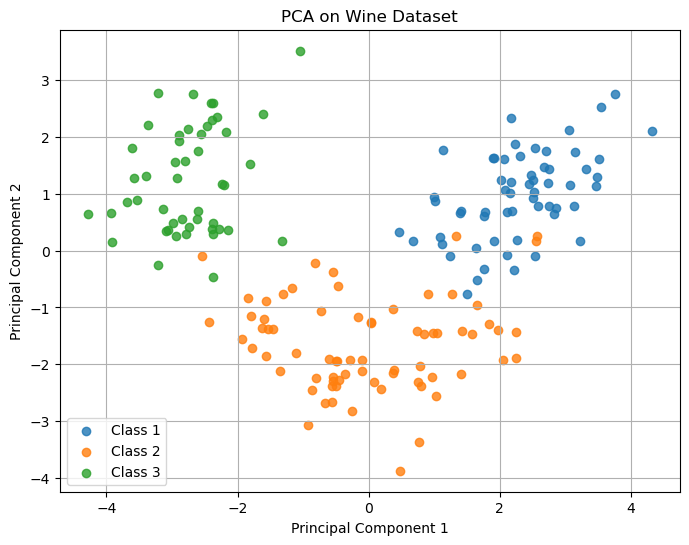

In [7]:

plt.figure(figsize=(8, 6))

for wine_class in sorted(pca_df["Wine_Class"].unique()):
    subset = pca_df[pca_df["Wine_Class"] == wine_class]
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Class {wine_class}",
        alpha=0.8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()


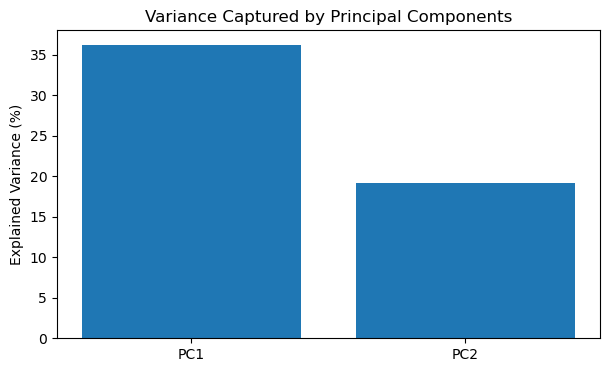

In [8]:

plt.figure(figsize=(7, 4))

plt.bar(
    ["PC1", "PC2"],
    pca.explained_variance_ratio_ * 100
)

plt.ylabel("Explained Variance (%)")
plt.title("Variance Captured by Principal Components")
plt.show()
